# 2013 — word2vec: Learning Word Embeddings

**Papers:** Tomas Mikolov et al., *"Efficient Estimation of Word Representations in Vector Space"* and *"Distributed Representations of Words and Phrases and their Compositionality"* (2013). Builds on Bengio et al.'s neural language model (2003).

**Distributional hypothesis:** "you shall know a word by the company it keeps". **Skip-gram with negative sampling (SGNS)** learns a vector $u_w$ for each word and $v_c$ for each context word, so that true (word, context) pairs score high and random pairs score low:

$$\mathcal L = -\log\sigma(u_w^\top v_c) - \sum_{k=1}^{K} \log\sigma(-u_w^\top v_{n_k}), \qquad n_k \sim P_{\text{noise}}(w) \propto \text{count}(w)^{3/4}$$

To keep this offline and fast we build a **synthetic corpus** from a small grammar: words of the same kind (animals, foods, royals, …) appear in similar contexts, which is the statistical structure word2vec exploits.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
from collections import Counter

PyTorch 2.15.0 | device: mps


In [2]:
groups = {
    "animal": ["cat", "dog", "horse", "rabbit", "tiger", "wolf"],
    "food": ["bread", "apple", "rice", "cheese", "soup", "cake"],
    "royal": ["king", "queen", "prince", "princess", "emperor", "duke"],
    "place": ["castle", "palace", "village", "forest", "city", "farm"],
    "tool": ["hammer", "knife", "shovel", "saw", "drill", "axe"],
}
templates = [
    ("the {animal} eats the {food}", 3), ("a hungry {animal} found some {food}", 2),
    ("the {animal} sleeps in the {place}", 2), ("the {royal} rules the {place}", 3),
    ("the {royal} lives in the {place}", 2), ("the {royal} eats {food} at the {place}", 1),
    ("the worker uses a {tool} at the {place}", 2), ("she cut the {food} with a {tool}", 1),
    ("the {royal} gave a {tool} to the worker", 1), ("a {animal} ran through the {place}", 2),
]
rng = np.random.default_rng(0)
weights = np.array([w for _, w in templates], float); weights /= weights.sum()
sentences = []
for _ in range(20000):
    t = templates[rng.choice(len(templates), p=weights)][0]
    sentences.append(t.format(**{g: rng.choice(ws) for g, ws in groups.items()}).split())
counts = Counter(w for s in sentences for w in s)
vocab = sorted(counts); stoi = {w: i for i, w in enumerate(vocab)}; V = len(vocab)
print(f"{len(sentences)} sentences, vocab {V}; e.g.:", " | ".join(" ".join(s) for s in sentences[:3]))

20000 sentences, vocab 50; e.g.: the queen eats apple at the castle | she cut the cheese with a saw | the worker uses a knife at the farm


## Build (center, context) pairs with window size 2

In [3]:
pairs = [(stoi[s[i]], stoi[s[j]]) for s in sentences for i in range(len(s))
         for j in range(max(0, i - 2), min(len(s), i + 3)) if i != j]
pairs = torch.tensor(pairs, device=device)
noise = torch.tensor([counts[w] ** 0.75 for w in vocab], device=device); noise /= noise.sum()
print("training pairs:", len(pairs))

training pairs: 369604


In [4]:
class SGNS(nn.Module):
    def __init__(self, V, d):
        super().__init__()
        self.inp = nn.Embedding(V, d); self.out = nn.Embedding(V, d)
        nn.init.uniform_(self.inp.weight, -0.5 / d, 0.5 / d); nn.init.zeros_(self.out.weight)
    def forward(self, w, c, neg):
        u = self.inp(w)                                        # (B, d)
        pos = F.logsigmoid((u * self.out(c)).sum(-1))
        negs = F.logsigmoid(-(self.out(neg) @ u.unsqueeze(-1)).squeeze(-1)).sum(-1)
        return -(pos + negs).mean()

model = SGNS(V, 32).to(device)
opt = torch.optim.Adam(model.parameters(), lr=0.01)
K, B = 5, 1024
for step in range(3000):
    batch = pairs[torch.randint(0, len(pairs), (B,), device=device)]
    neg = torch.multinomial(noise, B * K, replacement=True).view(B, K)
    loss = model(batch[:, 0], batch[:, 1], neg)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 600 == 0: print(f"step {step} loss {loss.item():.3f}")

step 0 loss 4.159


step 600 loss 1.858


step 1200 loss 1.884


step 1800 loss 1.841


step 2400 loss 1.878


## Nearest neighbours by cosine similarity
In this toy grammar, words in the same group are perfectly interchangeable, so similarities close to 1.0 are expected. Real corpora are messier, and neighbours there also capture finer relations.

In [5]:
E = F.normalize(model.inp.weight.detach(), dim=1).cpu()
def neighbours(w, k=5):
    sims = E @ E[stoi[w]]
    return [(vocab[i], round(sims[i].item(), 2)) for i in sims.argsort(descending=True)[1:k + 1]]
for w in ["cat", "cheese", "queen", "forest", "hammer"]:
    print(f"{w:8s} -> {neighbours(w)}")

cat      -> [('wolf', 1.0), ('rabbit', 1.0), ('horse', 1.0), ('tiger', 1.0), ('dog', 1.0)]
cheese   -> [('rice', 1.0), ('apple', 1.0), ('soup', 1.0), ('cake', 0.99), ('bread', 0.99)]
queen    -> [('prince', 1.0), ('princess', 1.0), ('emperor', 1.0), ('king', 1.0), ('duke', 1.0)]
forest   -> [('village', 1.0), ('city', 1.0), ('palace', 1.0), ('farm', 1.0), ('castle', 1.0)]
hammer   -> [('saw', 1.0), ('knife', 1.0), ('axe', 1.0), ('drill', 1.0), ('shovel', 1.0)]


## The embedding space (PCA to 2-D)
Words cluster by their role, and the model was never told the categories.

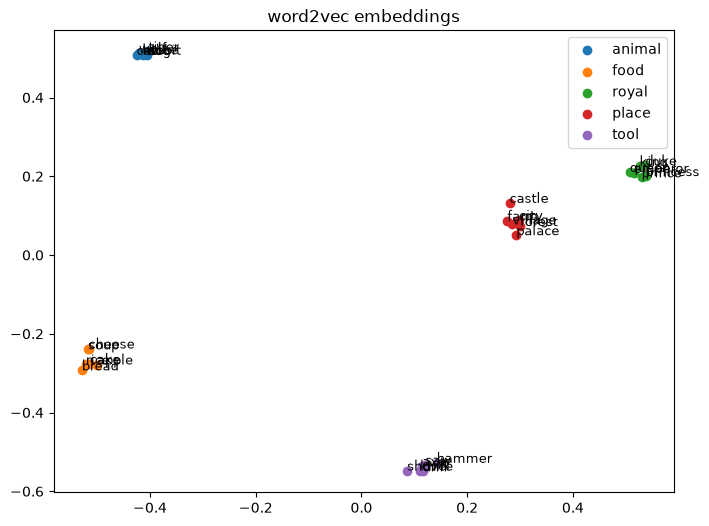

In [6]:
from sklearn.decomposition import PCA
words = [w for ws in groups.values() for w in ws]
Z = PCA(2).fit_transform(E[[stoi[w] for w in words]].numpy())
colors = {g: c for g, c in zip(groups, plt.cm.tab10.colors)}
plt.figure(figsize=(8, 6))
for w, z in zip(words, Z):
    g = next(g for g, ws in groups.items() if w in ws)
    plt.scatter(*z, color=colors[g]); plt.annotate(w, z, fontsize=9)
for g, c in colors.items(): plt.scatter([], [], color=c, label=g)
plt.legend(); plt.title("word2vec embeddings"); plt.show()

## Takeaways
- Words become dense vectors whose geometry encodes meaning. On large corpora this gives the famous analogies (king − man + woman ≈ queen).
- Every later language model starts with an embedding table like this one, now trained end-to-end inside the model.